# EMQA_L4_var_paths

**In the crisis FHS adapted within days; HS and the normal VaR lagged**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_var_paths/EMQA_L4_var_paths.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
START = pd.Timestamp('2015-01-01')
END = pd.Timestamp('2026-10-31')           # cut-off of Lecture 4: last complete month of the download
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO']].reindex(CAL)           # full calendar: missing days stay missing
X = P.diff()                           # daily change X_t = P_t - P_{t-1}; a change next to a gap is missing
print('daily prices', d(START), 'to', d(END), '| missing days in Romania:', int(P['RO'].isna().sum()))

daily prices 2015-01-01 to 2026-10-31 | missing days in Romania: 5


In [4]:
# the GARCH filter uses the arch package (not preinstalled on Google Colab)
import importlib.util, subprocess, sys
if importlib.util.find_spec('arch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model

## Rolling one-day-ahead VaR

For every day $t$ from 1 January 2017 to the cut-off the forecast uses changes up to $t-1$ only:

* **HS** (historical simulation): empirical $\alpha$-quantile of the last 365 changes;
* **normal**: $\hat\mu+\hat\sigma\,\Phi^{-1}(\alpha)$ on the same 365 changes;
* **Student-t**: maximum-likelihood $t$ fit on the same window ($\nu\ge 2.2$);
* **FHS** (filtered historical simulation): $\mathrm{VaR}_t=\mu_{d(t)}+\sigma_t\,\hat q_\alpha(z)$, weekday mean $\mu_d$, GARCH(1,1) volatility $\sigma_t$ and standardised residuals $z$, refitted every 21 days on 730 days;
* **EVT** (conditional extreme value theory): same filter, generalised Pareto tail above the 90% quantile of $z$.

This is the forecasting engine of the lecture (`analysis_L4.py`) without the simulations of the expected-shortfall test.

In [5]:
W_HS, W_G, REFIT, U_EVT = 365, 730, 21, 0.90
T0 = pd.Timestamp('2017-01-01')       # first backtest day


def fit_t(w):
    nu, loc, sc = stats.t.fit(w)
    if nu < 2.2:                       # keep a finite variance
        nu = 2.2
        _, loc, sc = stats.t.fit(w, f0=nu)
    return nu, loc, sc


def garch_filter(e):
    # GARCH(1,1), zero mean, Gaussian QMLE on the de-meaned changes
    res = arch_model(e, mean='Zero', vol='GARCH', p=1, q=1, dist='normal', rescale=False).fit(disp='off')
    return (float(res.params['omega']), float(res.params['alpha[1]']), float(res.params['beta[1]']),
            np.asarray(res.conditional_volatility))


def gpd_tail(z, u_q=U_EVT):
    # peaks over threshold: threshold u, GPD shape xi and scale beta (location 0)
    u = np.quantile(z, u_q)
    exc = z[z > u] - u
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    return u, xi, beta, len(exc), len(z)


def var_evt(tail, a):
    u, xi, beta, n_u, n = tail
    r = (n / n_u) * (1 - a)
    if abs(xi) < 1e-6:
        return u - beta * np.log(r)
    return u + beta / xi * (r ** (-xi) - 1)


def var_engine(xs, end, methods, levels):
    days = pd.date_range(T0, end, freq='D')
    out = {m: {a: np.full(len(days), np.nan) for a in levels} for m in methods}
    state = None
    for k, t in enumerate(days):
        hist = xs[:t - pd.Timedelta(days=1)].dropna()
        w = hist.values[-W_HS:]
        if 't' in methods:
            nu, loc, sc = fit_t(w)
        for a in levels:
            if 'hs' in methods:
                out['hs'][a][k] = np.quantile(w, a)
            if 'normal' in methods:
                out['normal'][a][k] = np.mean(w) + np.std(w, ddof=1) * stats.norm.ppf(a)
            if 't' in methods:
                out['t'][a][k] = loc + sc * stats.t.ppf(a, nu)
        if not {'fhs', 'evt'} & set(methods):
            continue
        if k % REFIT == 0:             # refit the filter on the last 730 changes
            hw = hist[-W_G:]
            mdow = hw.groupby(hw.index.dayofweek).mean()
            e = (hw - mdow.reindex(hw.index.dayofweek).values).values
            om, al, be, sw = garch_filter(e)
            z = e / sw
            state = {'om': om, 'al': al, 'be': be, 'mdow': mdow, 'z': np.sort(z), 'tail': gpd_tail(z),
                     's2': sw[-1] ** 2, 'e': e[-1], 'tlast': hw.index[-1]}
        while state['tlast'] < t - pd.Timedelta(days=1):    # advance sigma to t-1
            nxt = state['tlast'] + pd.Timedelta(days=1)
            state['s2'] = state['om'] + state['al'] * state['e'] ** 2 + state['be'] * state['s2']
            xv = xs.get(nxt, np.nan)
            state['e'] = (xv - state['mdow'][nxt.dayofweek]) if not np.isnan(xv) else np.sqrt(state['s2'])
            state['tlast'] = nxt
        s_t = np.sqrt(state['om'] + state['al'] * state['e'] ** 2 + state['be'] * state['s2'])
        m_t = state['mdow'][t.dayofweek]
        for a in levels:
            if 'fhs' in methods:
                out['fhs'][a][k] = m_t + s_t * np.quantile(state['z'], a)
            if 'evt' in methods:
                out['evt'][a][k] = m_t + s_t * var_evt(state['tail'], a)
    return days, out

In [6]:
import time
t0 = time.time()
METHODS = ['hs', 'normal', 't', 'fhs', 'evt']
DAYS, OUT = var_engine(X['RO'], END, METHODS, (0.99,))
print(f'{len(DAYS)} daily forecasts in {time.time() - t0:.0f} s')
x = X['RO'].reindex(DAYS).values
HITS = {m: pd.Series(np.where(np.isnan(x), np.nan, (x > OUT[m][0.99]).astype(float)), index=DAYS) for m in METHODS}

3591 daily forecasts in 40 s


In [7]:
a0, a1 = '2021-07-01', '2023-06-30'
for m in METHODS:
    show(f'vp.{m}', int(HITS[m][a0:a1].sum()))
n = int(HITS['hs'][a0:a1].notna().sum())
show('vp.n', n)
show('vp.exp', round(0.01 * n, 1))

vp.hs                        = 28
vp.normal                    = 45
vp.t                         = 29
vp.fhs                       = 19
vp.evt                       = 17
vp.n                         = 730
vp.exp                       = 7.3


In [8]:
COL = {'hs': PAL['BG'], 'normal': '#9a9a9a', 't': PAL['c7'], 'fhs': PAL['RO'], 'evt': PAL['DE_LU']}
LAB = {'hs': 'HS', 'normal': 'Normal', 't': 'Student-t', 'fhs': 'FHS', 'evt': 'EVT'}
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def month_axis(ax, step=1):
    # quarterly ticks fall on Jan/Apr/Jul/Oct, so every January (with its year) gets a label
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1, 13, step)) if step > 1 else mdates.MonthLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] +
                                               (f'\n{mdates.num2date(v).year}' if mdates.num2date(v).month == 1 else '')))

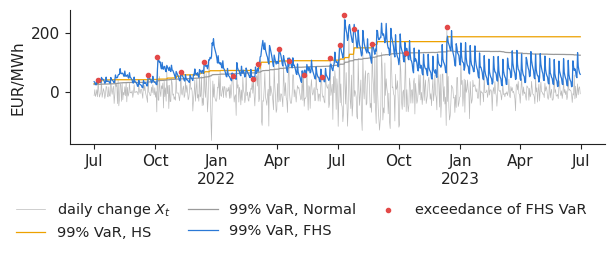

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 2.6))
xs = X['RO'][a0:a1]
ax.plot(xs.index, xs.values, color='#bbbbbb', lw=0.5, label='daily change $X_t$')
for m in ['hs', 'normal', 'fhs']:
    v = pd.Series(OUT[m][0.99], index=DAYS)[a0:a1]
    ax.plot(v.index, v.values, color=COL[m], lw=0.9, label='99% VaR, ' + LAB[m])
hh = HITS['fhs'][a0:a1]
hd = hh[hh == 1].index
ax.scatter(hd, X['RO'].reindex(hd), s=9, color=PAL['c8'], zorder=4, label='exceedance of FHS VaR')
ax.set_ylabel('EUR/MWh')
ax.set_ylim(-180, 280)
month_axis(ax, 3)
legend_bottom(fig, ncol=3)
fig.canvas.draw()
legend_top = max(lg.get_window_extent().y1 for lg in fig.legends) / fig.dpi
fig.tight_layout(rect=(0, max(legend_top - 0.08, 0.05) / fig.get_figheight(), 1, 1))
plt.savefig('var_paths.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()